# 02 · Панель по UCDP и базовые модели (проверка вслепую)

Что здесь:
1. Панель «страна × год» по UCDP GED (`src/seldon/panel.py`): погибшие на территории страны и целевые переменные.
2. Три базовые модели без признаков (`src/seldon/baseline.py`): `last`, `decay`, `base_rate`.
3. Проверка вслепую: учимся по год T, предсказываем T+1, T = 1995…2023.
4. Разрез по постсоветским странам: Грузия 2008, Украина 2014 и 2022, Армения/Азербайджан 2020.

Термины: **Brier score** — средний квадрат ошибки вероятности (меньше — лучше, 0 — идеал).
**AUC** — насколько хорошо модель ранжирует страны: 0.5 — наугад, 1 — идеально.
**Онсет** (`onset25`) — в этом году ≥25 погибших, а в прошлом — меньше.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from seldon import DATA_PROCESSED, PROJECT_ROOT
from seldon.core.entities import POST_SOVIET_GW, GW_TO_SHORT
from seldon.domains.conflict import baseline

pd.set_option("display.width", 160)
panel = pd.read_parquet(DATA_PROCESSED / "panel_country_year.parquet")
panel_m = pd.read_parquet(DATA_PROCESSED / "panel_country_month.parquet")
print(f"страна×год: {panel.shape}, стран {panel.gw.nunique()}, годы {panel.year.min()}–{panel.year.max()}")
print(f"страна×месяц: {panel_m.shape}")
panel.head()

страна×год: (6150, 9), стран 178, годы 1989–2024
страна×месяц: (73800, 11)


,gw,country,year,deaths_best,deaths_state,events,conflict25,conflict1000,onset25
0,2,United States of America,1989,0,0,0,0,0,0
1,2,United States of America,1990,0,0,0,0,0,0
2,2,United States of America,1991,0,0,0,0,0,0
3,2,United States of America,1992,0,0,0,0,0,0
4,2,United States of America,1993,0,0,0,0,0,0


## 1. Панель: сколько стран в конфликте по годам

year,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
conflict25,44,44,50,49,50,48,43,40,41,44,...,40,49,40,41,41,41,41,46,42,42
conflict1000,14,15,15,16,14,13,15,13,13,16,...,14,13,14,12,11,13,16,15,14,18
onset25,44,9,12,7,8,6,5,7,9,8,...,9,11,1,5,4,6,5,8,3,4
countries,151,152,165,168,170,170,170,170,170,170,...,174,174,174,174,174,174,174,174,174,174


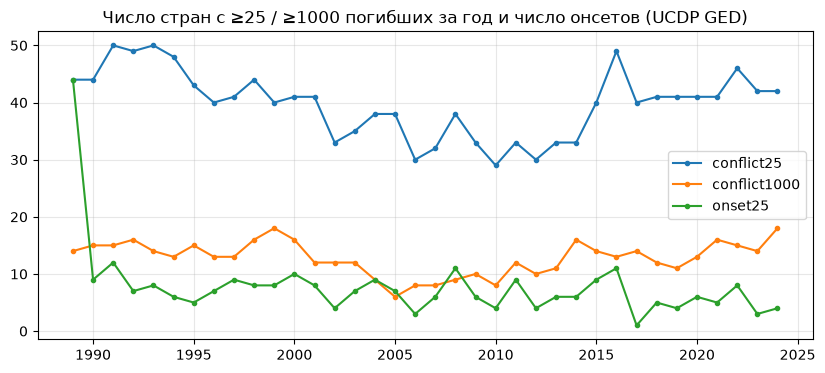

In [2]:
by_year = panel.groupby("year")[["conflict25", "conflict1000", "onset25"]].sum()
by_year["countries"] = panel.groupby("year").size()
ax = by_year[["conflict25", "conflict1000", "onset25"]].plot(figsize=(10, 4), marker=".")
ax.set_title("Число стран с ≥25 / ≥1000 погибших за год и число онсетов (UCDP GED)")
ax.set_xlabel(""); ax.grid(alpha=.3)
by_year.T

### Постсоветские страны: погибшие по годам (`deaths_best`)

In [3]:
ps = panel[panel.gw.isin(POST_SOVIET_GW)].copy()
ps["страна"] = ps.gw.map(GW_TO_SHORT)
tab = ps.pivot(index="страна", columns="year", values="deaths_best")
tab.style.format("{:.0f}").background_gradient(cmap="Reds", axis=None, vmax=5000)

year,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
страна,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Азербайджан,nan,nan,35,2856,1194,1489,55,5,29,34,18,13,6,0,0,8,24,5,12,30,7,20,21,16,11,46,63,137,36,16,9,7636,30,154,442,0
Армения,nan,nan,0,85,37,30,7,0,0,0,0,0,0,0,0,0,1,2,0,0,0,0,0,9,1,0,16,4,0,1,2,10,10,154,20,0
Беларусь,nan,nan,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Грузия,nan,nan,52,775,1837,0,52,0,26,38,0,0,0,0,0,27,0,0,0,621,0,3,0,0,0,0,0,0,0,0,0,0,0,0,1,0
Казахстан,nan,nan,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Кыргызстан,nan,nan,0,0,0,0,0,0,0,0,14,174,0,0,0,0,0,6,0,0,0,44,0,0,0,0,1,0,0,0,0,0,40,68,0,0
Латвия,nan,nan,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Литва,nan,nan,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Молдова,nan,nan,0,585,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Что видно: Украина в конфликте непрерывно с 2014 (Донбасс), поэтому 2022 для модели — **не онсет**,
а продолжение. Беларусь, Казахстан, Туркменистан, Балтия — нули все годы (в UCDP нет событий;
Казахстан-2022 в GED не попал, см. отчёт сессии 1).

## 2. Базовые модели: проверка вслепую

In [4]:
pred = baseline.predict_all(panel)
metrics = baseline.evaluate(pred)
summary = baseline.summarize(metrics)
print("выбранный полураспад decay по годам:", metrics.decay_half_life.value_counts().to_dict())
summary.round(4)

выбранный полураспад decay по годам: {1: 29}


,brier,auc,brier_onset,auc_onset
last,0.0754,0.8912,0.0480,NaN
decay,0.0595,0.9494,0.0436,0.7979
base_rate,0.1719,NaN,0.0767,NaN


Как читать: `brier`/`auc` — по всем странам (цель `conflict25` на T+1);
`brier_onset`/`auc_onset` — только по странам, где в году T конфликта **не было** (цель `onset25`).
`last` на онсетах даёт всем ноль, поэтому AUC не определён; `base_rate` даёт всем одно число — AUC тоже не определён.

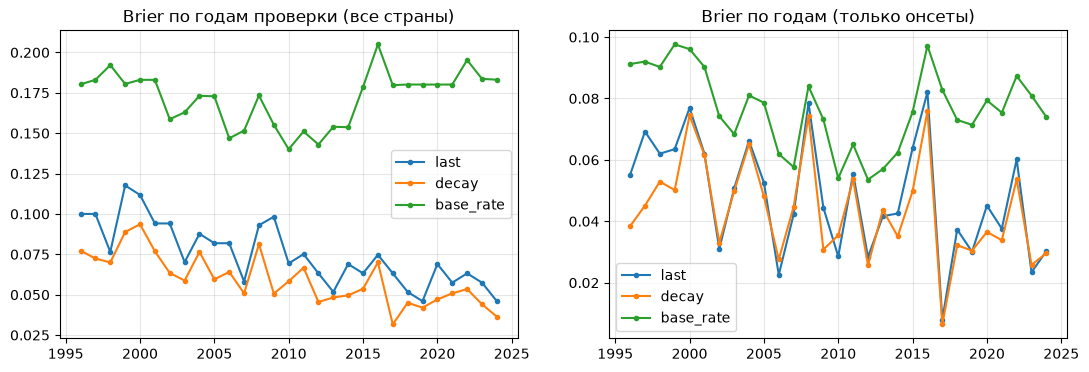

,n_countries,n_conflict,n_at_risk,n_onset,decay_half_life,last_brier,last_auc,last_brier_onset,last_auc_onset,decay_brier,decay_auc,decay_brier_onset,decay_auc_onset,base_rate_brier,base_rate_auc,base_rate_brier_onset,base_rate_auc_onset
year,,,,,,,,,,,,,,,,,
1996,170,40,127,7,1,0.100,0.874,0.055,NaN,0.077,0.936,0.038,0.810,0.180,NaN,0.091,NaN
1997,170,41,130,9,1,0.100,0.859,0.069,NaN,0.072,0.948,0.045,0.882,0.183,NaN,0.092,NaN
1998,170,44,129,8,1,0.076,0.889,0.062,NaN,0.070,0.930,0.053,0.724,0.192,NaN,0.090,NaN
1999,170,40,126,8,1,0.118,0.854,0.063,NaN,0.089,0.927,0.050,0.808,0.180,NaN,0.098,NaN
2000,170,41,130,10,1,0.112,0.843,0.077,NaN,0.094,0.912,0.074,0.741,0.183,NaN,0.096,NaN
2001,170,41,129,8,1,0.094,0.871,0.062,NaN,0.077,0.885,0.062,0.486,0.183,NaN,0.090,NaN
2002,170,33,129,4,1,0.094,0.896,0.031,NaN,0.063,0.951,0.033,0.754,0.159,NaN,0.074,NaN
2003,171,35,138,7,1,0.070,0.882,0.051,NaN,0.059,0.924,0.050,0.665,0.163,NaN,0.068,NaN
2004,171,38,136,9,1,0.088,0.859,0.066,NaN,0.076,0.938,0.065,0.794,0.173,NaN,0.081,NaN


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for m in baseline.MODELS:
    axes[0].plot(metrics.year, metrics[f"{m}_brier"], marker=".", label=m)
    axes[1].plot(metrics.year, metrics[f"{m}_brier_onset"], marker=".", label=m)
axes[0].set_title("Brier по годам проверки (все страны)"); axes[1].set_title("Brier по годам (только онсеты)")
for ax in axes: ax.grid(alpha=.3); ax.legend()
plt.show()
metrics.set_index("year").round(3)

## 3. Постсоветский разрез: что модели давали на ключевые годы

In [6]:
cases = [(372, 2008), (369, 2014), (369, 2022), (371, 2020), (373, 2020)]
rows = []
for gw, y in cases:
    r = pred[(pred.gw == gw) & (pred.year == y)].iloc[0]
    rows.append({"страна": GW_TO_SHORT[gw], "год": y,
                 "last": r["last"], "decay": r["decay"], "base_rate": r["base_rate"],
                 "факт conflict25": int(r.conflict25), "факт onset25": int(r.onset25),
                 "был ли конфликт в T": int(1 - r.at_risk),
                 "погибших": int(panel[(panel.gw == gw) & (panel.year == y)].deaths_best.iloc[0])})
pd.DataFrame(rows).style.format({"last": "{:.2f}", "decay": "{:.3f}", "base_rate": "{:.2f}"})

,страна,год,last,decay,base_rate,факт conflict25,факт onset25,был ли конфликт в T,погибших
0,Грузия,2008,0.00,0.064,0.19,1,1,0,621
1,Украина,2014,0.00,0.000,0.19,1,1,0,4946
2,Украина,2022,1.00,0.996,0.24,1,0,1,92615
3,Армения,2020,0.00,0.000,0.24,0,0,0,10
4,Азербайджан,2020,0.00,0.235,0.24,1,1,0,7636


Итог по кейсам: три из четырёх онсетов (Грузия 2008, Украина 2014, Азербайджан 2020) базовые модели
не видели — вероятность от 0 до 23%, то есть не выше фона. Украина 2022 — «предсказана» лишь потому,
что конфликт на Донбассе не прекращался с 2014. Это и есть планка, которую должна побить любая
следующая модель: не повторить `decay` в среднем, а дать этим онсетам вероятность выше фона.

### Все прогнозы `decay` по постсоветским странам (вероятность ≥25 погибших в следующем году)

In [7]:
pp = pred[pred.gw.isin(POST_SOVIET_GW)].copy()
pp["страна"] = pp.gw.map(GW_TO_SHORT)
dec = pp.pivot(index="страна", columns="year", values="decay")
dec.style.format("{:.2f}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=1)

year,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
страна,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Азербайджан,1.00,0.50,0.75,0.88,0.44,0.22,0.11,0.05,0.03,0.01,0.01,0.00,0.00,0.50,0.25,0.13,0.06,0.03,0.02,0.51,0.75,0.88,0.94,0.47,0.23,0.62,0.81,0.90,0.95
Армения,0.44,0.22,0.11,0.05,0.03,0.01,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.50,0.25
Беларусь,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Грузия,0.75,0.38,0.69,0.84,0.42,0.21,0.11,0.05,0.03,0.51,0.26,0.13,0.06,0.53,0.27,0.13,0.07,0.03,0.02,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Казахстан,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Кыргызстан,0.00,0.00,0.00,0.00,0.00,0.50,0.25,0.12,0.06,0.03,0.02,0.01,0.00,0.00,0.00,0.50,0.25,0.13,0.06,0.03,0.02,0.01,0.00,0.00,0.00,0.00,0.50,0.75,0.38
Латвия,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Литва,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Молдова,0.06,0.03,0.02,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
